# 营销渠道效果与变体描述性比较

**业务问题：** 各渠道的 CTR、CPA、ROAS 怎样？同渠道内不同变体的观测表现如何？

> 本项目使用仓库内的合成教学数据，不代表真实企业业绩。笔记本复用同目录分析模块，确保脚本、结果表与图表口径一致。请使用 Python 3.11 并从仓库内部启动 Jupyter。

## 1. 读取数据

根据当前目录向上定位仓库，不在 notebook 中依赖 `__file__`，也不硬编码电脑路径。

In [1]:
from pathlib import Path
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO

# Works when Jupyter starts at the repo root, project directory or notebook directory.
start = Path.cwd().resolve()
root = next((p for p in (start, *start.parents)
             if (p / 'projects' / 'marketing-campaign-evaluation' / 'scripts' / 'analyze.py').is_file()), None)
if root is None:
    raise FileNotFoundError('请在本仓库内启动 Jupyter，或先切换到仓库根目录。')
project_dir = root / 'projects' / 'marketing-campaign-evaluation'
module_path = project_dir / 'scripts' / 'analyze.py'
spec = importlib.util.spec_from_file_location('marketing_campaign_evaluation', module_path)
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
df = analysis.load_data()
assert not df.empty
print('Input rows:', len(df))
display(df.head())


Input rows: 15


,campaign_id,channel,campaign_type,start_date,end_date,impressions,clicks,spend,revenue,conversions,variant,age_group
0,CMP010,Display,Awareness,2024-01-15,2024-01-30,200000,4000,6000,15000,20,Control,45-54
1,CMP011,Display,Awareness,2024-01-15,2024-01-30,200000,4200,6000,15800,22,VariantA,45-54
2,CMP012,Display,Awareness,2024-01-15,2024-01-30,200000,4100,6000,15500,21,VariantB,45-54
3,CMP004,Email,Conversion,2024-01-05,2024-01-20,10000,950,800,4500,38,Control,35-44
4,CMP005,Email,Conversion,2024-01-05,2024-01-20,10000,980,800,4900,42,VariantA,35-44


## 2. 数据质量检查

报告缺失与整行重复。重复事件可能是真实行为，不应未经业务判断直接删除。分析模块进一步校验必要字段和数值范围。

In [2]:
display(df.isna().sum().to_frame('missing_count'))
print('Exact duplicate rows:', int(df.duplicated().sum()))

,missing_count
campaign_id,0
channel,0
campaign_type,0
start_date,0
end_date,0
impressions,0
clicks,0
spend,0
revenue,0
conversions,0


Exact duplicate rows: 0


## 3. 指标定义与独立复算

CTR = 点击数 / 曝光数；CVR = 转化数 / 点击数；CPA = 广告支出 / 转化数；ROAS = 营收 / 广告支出。聚合后使用分子分母的总和相除，而非简单平均各行比率。仅凭变体标签不能认定随机 A/B 实验，更不能宣称统计显著。

In [3]:
channel_check = df.groupby('channel')[['impressions', 'clicks', 'spend', 'revenue', 'conversions']].sum()
channel_check['ctr_pct'] = channel_check['clicks'] / channel_check['impressions'] * 100
channel_check['cpa'] = channel_check['spend'] / channel_check['conversions']
channel_check['roas'] = channel_check['revenue'] / channel_check['spend']
display(channel_check.round(3))

,impressions,clicks,spend,revenue,conversions,ctr_pct,cpa,roas
channel,,,,,,,,
Display,600000,12300,18000,46300,63,2.050,285.714,2.572
Email,30000,2950,2400,14500,125,9.833,19.200,6.042
Search,90000,5550,9600,38300,132,6.167,72.727,3.990
Social Media,150000,7000,7500,27300,145,4.667,51.724,3.640
Video,240000,17400,21000,70500,113,7.250,185.841,3.357


## 4. 完整分析结果

下面调用可复用的 `analyze(df)`，展示结果表；业务口径详见相邻项目说明和脚本。

In [4]:
results = analysis.analyze(df)
assert isinstance(results, dict) and results
for name, table in results.items():
    print(f'--- {name} ---')
    with pd.option_context('display.max_rows', 50, 'display.max_columns', 20):
        display(table)

--- overview ---


,campaign_count,impressions,clicks,spend,revenue,conversions,ctr_pct,cvr_pct,cpc,cpm,cpa,roas,revenue_minus_ad_spend,ad_spend_return_proxy_pct
0,15,1110000,45200,58500,196900,578,4.072072,1.278761,1.294248,52.702703,101.211073,3.365812,138400,236.581197


--- campaign_metrics ---


,campaign_id,channel,campaign_type,start_date,end_date,impressions,clicks,spend,revenue,conversions,variant,age_group,ctr_pct,cvr_pct,cpc,cpm,cpa,roas,revenue_minus_ad_spend,ad_spend_return_proxy_pct
0,CMP010,Display,Awareness,2024-01-15,2024-01-30,200000,4000,6000,15000,20,Control,45-54,2.000000,0.500000,1.500000,30.000000,300.000000,2.500000,9000,150.000000
1,CMP011,Display,Awareness,2024-01-15,2024-01-30,200000,4200,6000,15800,22,VariantA,45-54,2.100000,0.523810,1.428571,30.000000,272.727273,2.633333,9800,163.333333
2,CMP012,Display,Awareness,2024-01-15,2024-01-30,200000,4100,6000,15500,21,VariantB,45-54,2.050000,0.512195,1.463415,30.000000,285.714286,2.583333,9500,158.333333
3,CMP004,Email,Conversion,2024-01-05,2024-01-20,10000,950,800,4500,38,Control,35-44,9.500000,4.000000,0.842105,80.000000,21.052632,5.625000,3700,462.500000
4,CMP005,Email,Conversion,2024-01-05,2024-01-20,10000,980,800,4900,42,VariantA,35-44,9.800000,4.285714,0.816327,80.000000,19.047619,6.125000,4100,512.500000
5,CMP006,Email,Conversion,2024-01-05,2024-01-20,10000,1020,800,5100,45,VariantB,35-44,10.200000,4.411765,0.784314,80.000000,17.777778,6.375000,4300,537.500000
6,CMP007,Search,Conversion,2024-01-10,2024-01-25,30000,1800,3200,12000,40,Control,18-24,6.000000,2.222222,1.777778,106.666667,80.000000,3.750000,8800,275.000000
7,CMP008,Search,Conversion,2024-01-10,2024-01-25,30000,1850,3200,12800,44,VariantA,18-24,6.166667,2.378378,1.729730,106.666667,72.727273,4.000000,9600,300.000000
8,CMP009,Search,Conversion,2024-01-10,2024-01-25,30000,1900,3200,13500,48,VariantB,18-24,6.333333,2.526316,1.684211,106.666667,66.666667,4.218750,10300,321.875000
9,CMP001,Social Media,Awareness,2024-01-01,2024-01-14,50000,2250,2500,8750,45,Control,25-34,4.500000,2.000000,1.111111,50.000000,55.555556,3.500000,6250,250.000000


--- channel_performance ---


,channel,impressions,clicks,spend,revenue,conversions,campaign_count,ctr_pct,cvr_pct,cpc,cpm,cpa,roas,revenue_minus_ad_spend,ad_spend_return_proxy_pct
0,Display,600000,12300,18000,46300,63,3,2.050000,0.512195,1.463415,30.000000,285.714286,2.572222,28300,157.222222
1,Email,30000,2950,2400,14500,125,3,9.833333,4.237288,0.813559,80.000000,19.200000,6.041667,12100,504.166667
2,Search,90000,5550,9600,38300,132,3,6.166667,2.378378,1.729730,106.666667,72.727273,3.989583,28700,298.958333
3,Social Media,150000,7000,7500,27300,145,3,4.666667,2.071429,1.071429,50.000000,51.724138,3.640000,19800,264.000000
4,Video,240000,17400,21000,70500,113,3,7.250000,0.649425,1.206897,87.500000,185.840708,3.357143,49500,235.714286


--- variant_comparison ---


,channel,campaign_type,start_date,end_date,age_group,variant,impressions,clicks,spend,revenue,...,revenue_minus_ad_spend,ad_spend_return_proxy_pct,variants_in_group,control_cvr_pct,control_roas,has_control,comparable_group,cvr_delta_pp_vs_control,relative_cvr_change_pct_vs_control,roas_delta_vs_control
0,Display,Awareness,2024-01-15,2024-01-30,45-54,Control,200000,4000,6000,15000,...,9000,150.000000,3,0.500000,2.500000,True,True,0.000000,0.000000,0.000000
1,Display,Awareness,2024-01-15,2024-01-30,45-54,VariantA,200000,4200,6000,15800,...,9800,163.333333,3,0.500000,2.500000,True,True,0.023810,4.761905,0.133333
2,Display,Awareness,2024-01-15,2024-01-30,45-54,VariantB,200000,4100,6000,15500,...,9500,158.333333,3,0.500000,2.500000,True,True,0.012195,2.439024,0.083333
3,Email,Conversion,2024-01-05,2024-01-20,35-44,Control,10000,950,800,4500,...,3700,462.500000,3,4.000000,5.625000,True,True,0.000000,0.000000,0.000000
4,Email,Conversion,2024-01-05,2024-01-20,35-44,VariantA,10000,980,800,4900,...,4100,512.500000,3,4.000000,5.625000,True,True,0.285714,7.142857,0.500000
5,Email,Conversion,2024-01-05,2024-01-20,35-44,VariantB,10000,1020,800,5100,...,4300,537.500000,3,4.000000,5.625000,True,True,0.411765,10.294118,0.750000
6,Search,Conversion,2024-01-10,2024-01-25,18-24,Control,30000,1800,3200,12000,...,8800,275.000000,3,2.222222,3.750000,True,True,0.000000,0.000000,0.000000
7,Search,Conversion,2024-01-10,2024-01-25,18-24,VariantA,30000,1850,3200,12800,...,9600,300.000000,3,2.222222,3.750000,True,True,0.156156,7.027027,0.250000
8,Search,Conversion,2024-01-10,2024-01-25,18-24,VariantB,30000,1900,3200,13500,...,10300,321.875000,3,2.222222,3.750000,True,True,0.304094,13.684211,0.468750
9,Social Media,Awareness,2024-01-01,2024-01-14,25-34,Control,50000,2250,2500,8750,...,6250,250.000000,3,2.000000,3.500000,True,True,0.000000,0.000000,0.000000


--- age_group_performance ---


,age_group,impressions,clicks,spend,revenue,conversions,campaign_count,ctr_pct,cvr_pct,cpc,cpm,cpa,roas,revenue_minus_ad_spend,ad_spend_return_proxy_pct
0,18-24,90000,5550,9600,38300,132,3,6.166667,2.378378,1.729730,106.666667,72.727273,3.989583,28700,298.958333
1,25-34,390000,24400,28500,97800,258,6,6.256410,1.057377,1.168033,73.076923,110.465116,3.431579,69300,243.157895
2,35-44,30000,2950,2400,14500,125,3,9.833333,4.237288,0.813559,80.000000,19.200000,6.041667,12100,504.166667
3,45-54,600000,12300,18000,46300,63,3,2.050000,0.512195,1.463415,30.000000,285.714286,2.572222,28300,157.222222


## 5. 可视化

图表与脚本使用同一结果字典，不另写一套计算逻辑。

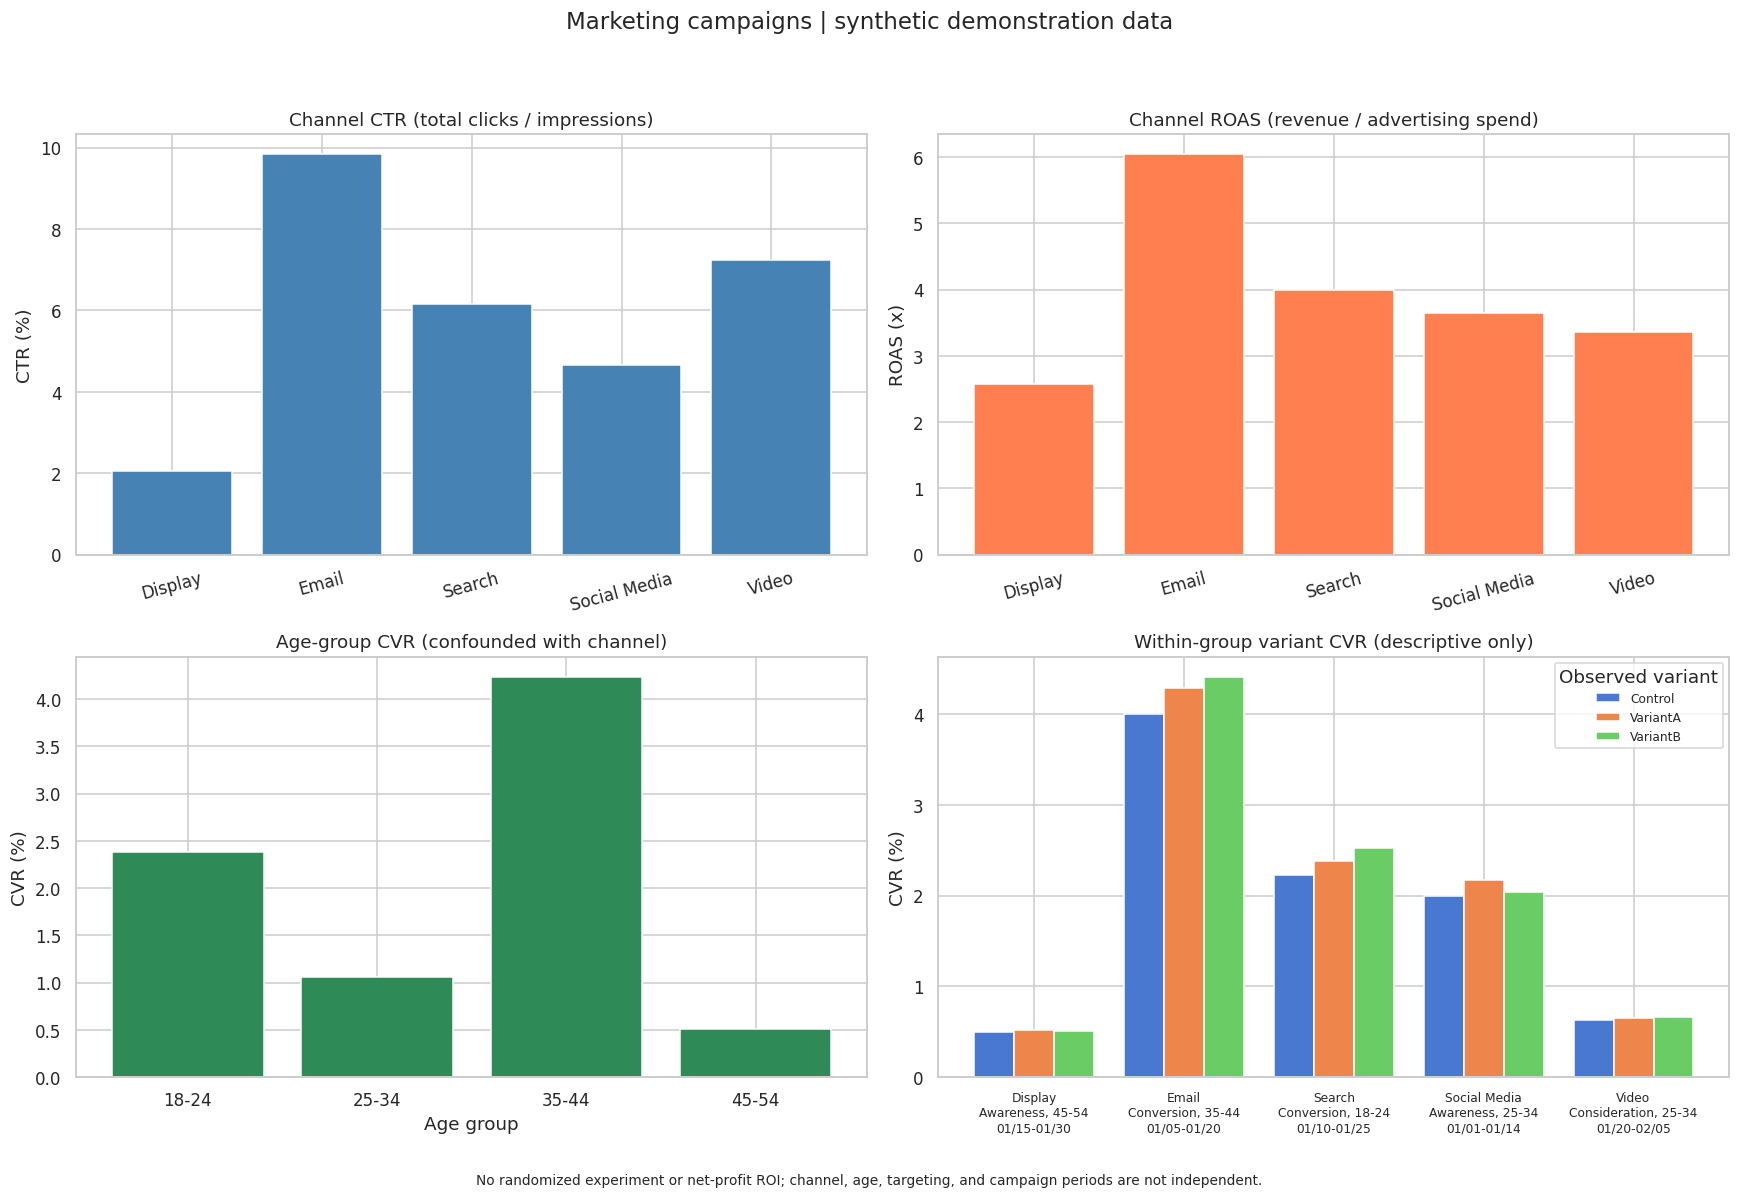

In [5]:
fig = analysis.plot_dashboard(results)
# Explicit PNG display also works with the headless Agg backend.
image = BytesIO()
fig.savefig(image, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image.getvalue()))
plt.close(fig)

## 6. 结论、建议与边界

Email 在这份合成样本中的 CTR 约为 9.83%、CPA 为 19.20、ROAS 约为 6.04。广告支出回报代理不等同于净利润 ROI，也没有新客户信息支持 CAC。渠道和年龄段存在混杂，不能把差异归因于年龄；变体比较只报告观测差异，不生成无依据的显著性结论。

**复现检查：** 从首个代码单元开始运行全部单元；仓库统一验证命令为 `python scripts/validate_portfolio.py`。生成笔记本和实际执行笔记本是两个不同步骤，执行结果以验证报告为准。